I0000 00:00:1793451994.767836   10454 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793451994.768586   10454 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793451994.820637   10454 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793451996.607039   10454 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


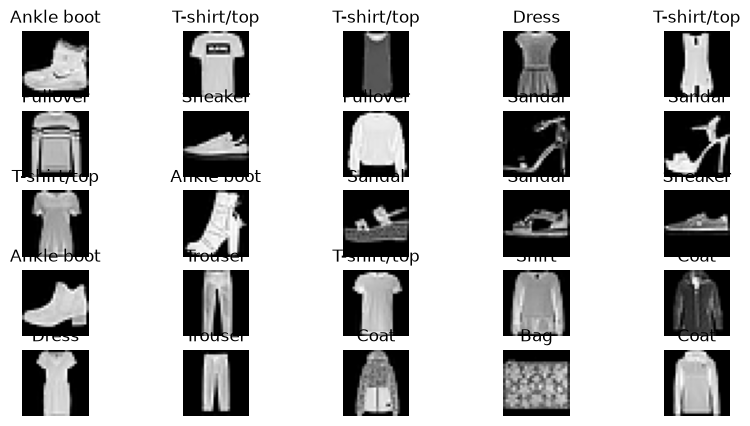

/home/ubuntu/.venv/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1793452000.560691   10454 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8268 - loss: 0.4909
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8674 - loss: 0.3697
Epoch 3/10
 820/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8782 - loss: 0.3394

In [ ]:
# Импорт необходимых библиотек
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Установка seed для воспроизводимости результатов
keras.utils.set_random_seed(42)

# Загрузка и подготовка данных
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Нормализация данных
x_train = x_train / 255.0
x_test = x_test / 255.0

# Создание списка меток классов
labels = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
          "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Визуализация первых 25 изображений
plt.figure(figsize=(10, 5))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(labels[y_train[i]])
    plt.axis('off')
plt.show()

# Создание модели
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),  # Преобразование матрицы в вектор
    keras.layers.Dense(128, activation='relu'),  # Скрытый слой
    keras.layers.Dense(10, activation='softmax')  # Выходной слой
])

# Компиляция модели
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Обучение модели
model.fit(x_train, y_train, epochs=10)

# Оценка модели
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Точность на тестовых данных: {test_acc*100:.2f}%')

# Обработка предупреждения о выделении памяти
# Если появляется предупреждение о выделении памяти, можно попробовать:
# 1. Уменьшить размер батчей
# 2. Использовать более простую архитектуру модели
# 3. Увеличить объем доступной памяти
# 4. Использовать GPU вместо CPU

# Дополнительная информация:
# При работе с большими моделями или наборами данных может появиться предупреждение:
# "Выделение X превышает 10% свободной системной памяти"
# Это означает, что модель использует слишком много памяти.
# В этом случае можно попробовать уменьшить размер модели или использовать более мощное оборудование.
